# Survival Lab

We've looked at normal-linear regression and probit regression from a likelihood perspective, which yields two log-likelihoods:
$$
LL(\beta,\sigma) = - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2
$$
and
$$
LL(\beta) = \sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma)).
$$
This lab combines them by looking at **right-censored** survival data.

We are going to use the Metabric breast cancer dataset to predict how long someone survives after being treated for breast cancer. For the regressions that follow, include the following as numeric variables:

- 'Age at Diagnosis'
- 'Lymph nodes examined positive'
- 'Mutation Count'
- 'Tumor Size'

and the following as categorical variables (one-hot encode them):

- 'Chemotherapy'
- 'Hormone Therapy'
- 'Radio Therapy'
- 'Tumor Stage'

The outcome variable of interest is the log of `Overall Survival (Months)`, which we'll refer to as log-months.

1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**
2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.
3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).
4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.
5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

In [1]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder

from lifelines import LogNormalAFTFitter

In [2]:
df = pd.read_csv('data/metabric.csv')
df.head()

,Age at Diagnosis,Type of Breast Surgery,Cancer Type,Chemotherapy,Hormone Therapy,Lymph nodes examined positive,Mutation Count,Nottingham prognostic index,Overall Survival (Months),Overall Survival Status,Radio Therapy,TMB (nonsynonymous),Tumor Size,Tumor Stage
0,43.19,BREAST CONSERVING,Breast Cancer,NO,YES,0.0,2.0,4.020,84.633333,0:LIVING,YES,2.615035,10.0,1.0
1,48.87,MASTECTOMY,Breast Cancer,YES,YES,1.0,2.0,4.030,163.700000,1:DECEASED,NO,2.615035,15.0,2.0
2,47.68,MASTECTOMY,Breast Cancer,YES,YES,3.0,1.0,4.050,164.933333,0:LIVING,YES,1.307518,25.0,2.0
3,76.97,MASTECTOMY,Breast Cancer,YES,YES,8.0,2.0,6.080,41.366667,1:DECEASED,YES,2.615035,40.0,2.0
4,78.77,MASTECTOMY,Breast Cancer,NO,YES,0.0,4.0,4.062,7.800000,1:DECEASED,YES,5.230071,31.0,4.0


# Problem 1

In [3]:
df['Overall Survival Status'].value_counts().to_frame()

,count
Overall Survival Status,
1:DECEASED,768
0:LIVING,575


768 are deceased, while 575 are alive.

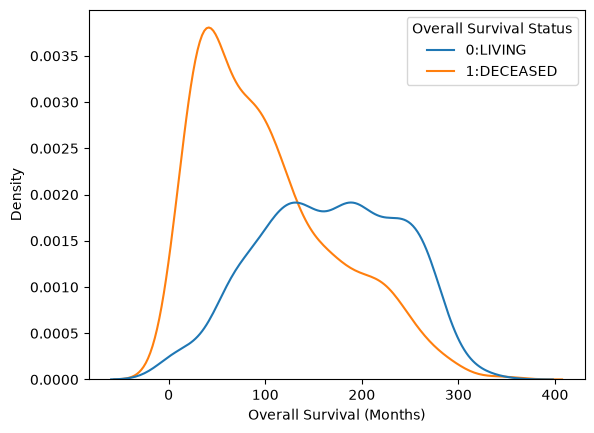

In [4]:
sns.kdeplot(df, x='Overall Survival (Months)', hue='Overall Survival Status')
plt.show()

In [5]:
df = df.query("`Tumor Stage` != 0").reset_index(drop=True)

# Problem 2

In [6]:
X = df[['Age at Diagnosis', 'Lymph nodes examined positive', 'Mutation Count', 'Tumor Size',
        'Chemotherapy', 'Hormone Therapy', 'Radio Therapy', 'Tumor Stage']]
y = np.log(df['Overall Survival (Months)'])

In [7]:
X_drop = X[df['Overall Survival Status'] != '0:LIVING']
y_drop = y[df['Overall Survival Status'] != '0:LIVING']

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=19)
X_drop_train, X_drop_test, y_drop_train, y_drop_test = train_test_split(X_drop, y_drop, test_size=0.2, random_state=19)

In [9]:
ct = make_column_transformer(
    (OneHotEncoder(drop='first'), ['Chemotherapy', 'Hormone Therapy', 'Radio Therapy', 'Tumor Stage']),
    remainder='passthrough'
)

model = make_pipeline(
    ct,
    LinearRegression()
)

coef = pd.DataFrame()

In [10]:
model1 = model.fit(X_train, y_train)

coef['Model 1'] = [model1[1].intercept_] + list(model1[1].coef_)

pred1 = np.exp(pd.DataFrame({
    'Pred' : model1.predict(X_test),
    'True' : y_test
}))

In [11]:
model2 = model.fit(X_drop_train, y_drop_train)

coef['Model 2'] = [model2[1].intercept_] + list(model2[1].coef_)

pred2 = np.exp(pd.DataFrame({
    'Pred' : model1.predict(X_drop_test),
    'True' : y_drop_test
}))

In [ ]:
coef.index = list(model[:1].get_feature_names_out()) + ['Intercept']
coef.round(2)

,Model 1,Model 2
Intercept,5.36,4.56
onehotencoder__Chemotherapy_YES,-0.27,-0.35
onehotencoder__Hormone Therapy_YES,0.07,0.26
onehotencoder__Radio Therapy_YES,0.05,0.05
onehotencoder__Tumor Stage_2.0,-0.20,-0.27
onehotencoder__Tumor Stage_3.0,-0.43,-0.54
onehotencoder__Tumor Stage_4.0,-0.71,-0.92
remainder__Age at Diagnosis,-0.01,-0.00
remainder__Lymph nodes examined positive,-0.03,-0.03
remainder__Mutation Count,0.01,0.02


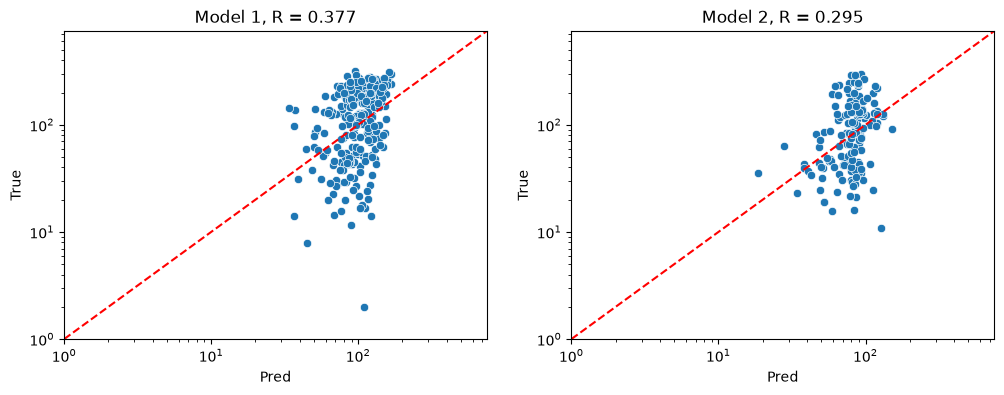

In [13]:
fig, axs = plt.subplots(ncols=2, figsize=(12, 4))

sns.scatterplot(pred1, ax=axs[0], x='Pred', y='True').set(xscale='log', yscale='log')
axs[0].plot([1, 750], [1, 750], color='red', linestyle='--')
axs[0].set(xlim=(1, 750), ylim=(1, 750), title=f'Model 1, R = {pred1.corr().loc['Pred', 'True']:.3f}')

sns.scatterplot(pred2, ax=axs[1], x='Pred', y='True').set(xscale='log', yscale='log')
axs[1].plot([1, 750], [1, 750], color='red', linestyle='--')
axs[1].set(xlim=(1, 750), ylim=(1, 750), title=f'Model 2, R = {pred2.corr().loc['Pred', 'True']:.3f}')

plt.show()

Both models perform poorly on the test data, with there being very little correlation between true values and our predictions.

The first model uses imputation, since it replaces the "missing" data for surviving patients with our best estimate of survival time. In this case, that estimate is their survival time up until the study is complete. The second model just drops that missing data instead.

# Problem 3

P(t) = p[x = t] (density) if the patient dies, p[x > t] (cumulative) if the patient survives

$$
    LL(\beta,\sigma) = \delta_i (- n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2) +
                       (1-\delta_i) \sum_{i=1}^N \log(1-\Phi(x_i \cdot \beta/\sigma))
$$

$\delta_i = $ 0 if the patient survives, 1 otherwise 

# Problem 4

In [14]:
aft_input = pd.DataFrame(ct.fit_transform(X), columns=model1[:1].get_feature_names_out())

aft_input[
    ['Overall Survival (Months)', 'Overall Survival Status']
] = df[
    ['Overall Survival (Months)', 'Overall Survival Status']
]

aft_input['Overall Survival Status'] = aft_input['Overall Survival Status'].map(lambda s : int(s[0]))

aft_input.head()

,onehotencoder__Chemotherapy_YES,onehotencoder__Hormone Therapy_YES,onehotencoder__Radio Therapy_YES,onehotencoder__Tumor Stage_2.0,onehotencoder__Tumor Stage_3.0,onehotencoder__Tumor Stage_4.0,remainder__Age at Diagnosis,remainder__Lymph nodes examined positive,remainder__Mutation Count,remainder__Tumor Size,Overall Survival (Months),Overall Survival Status
0,0.0,1.0,1.0,0.0,0.0,0.0,43.19,0.0,2.0,10.0,84.633333,0
1,1.0,1.0,0.0,1.0,0.0,0.0,48.87,1.0,2.0,15.0,163.700000,1
2,1.0,1.0,1.0,1.0,0.0,0.0,47.68,3.0,1.0,25.0,164.933333,0
3,1.0,1.0,1.0,1.0,0.0,0.0,76.97,8.0,2.0,40.0,41.366667,1
4,0.0,1.0,1.0,0.0,0.0,1.0,78.77,0.0,4.0,31.0,7.800000,1


In [15]:
aft_train, aft_test = train_test_split(aft_input, test_size=0.2, random_state=19)

In [16]:
model3 = LogNormalAFTFitter().fit(aft_train, duration_col='Overall Survival (Months)', event_col='Overall Survival Status')

# Problem 5

In [58]:
coef['Model 3'] = model3.summary.loc['mu_']['coef']
coef.round(2)

,Model 1,Model 2,Model 3
Intercept,5.36,4.56,6.88
onehotencoder__Chemotherapy_YES,-0.27,-0.35,-0.35
onehotencoder__Hormone Therapy_YES,0.07,0.26,0.25
onehotencoder__Radio Therapy_YES,0.05,0.05,0.14
onehotencoder__Tumor Stage_2.0,-0.20,-0.27,-0.28
onehotencoder__Tumor Stage_3.0,-0.43,-0.54,-0.60
onehotencoder__Tumor Stage_4.0,-0.71,-0.92,-0.93
remainder__Age at Diagnosis,-0.01,-0.00,-0.02
remainder__Lymph nodes examined positive,-0.03,-0.03,-0.05
remainder__Mutation Count,0.01,0.02,-0.02


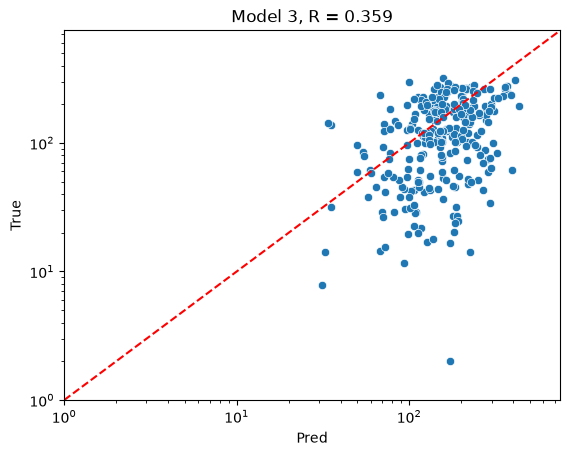

In [60]:
pred3 = pd.DataFrame({
    'Pred' : model3.predict_median(aft_test),
    'True' : np.exp(y_test)
})

sns.scatterplot(pred3, x='Pred', y='True').set(xscale='log', yscale='log')
plt.plot([1, 750], [1, 750], color='red', linestyle='--')
plt.xlim(1, 750)
plt.ylim(1, 750)
plt.title(f'Model 3, R = {pred3.corr().loc['Pred', 'True']:.3f}')
plt.show()

This model performs about the same as the first 2 models. The coefficients are very similar as well. Model 1 does not give much weight to `Hormone Therapy`, while the other models do. Also, Model 3 gives the most weight to `Radio Therapy`. Otherwise, the models are almost the same.